# Milestone 1 — Hiệu năng Scraper arXiv: Phân tích Benchmark Phân tán

**Nhóm Đồ án NMKHDL** · Khoa Toán - Tin học, HCMUS · Môn Nhập môn Khoa học Dữ liệu  
**Thành viên thực hiện:** Nguyễn Đức Anh Khôi (24120076), Nguyễn Quang Phát (24120117), Đoàn Ngọc Bảo (24120168), Trần Nguyễn Quốc Khánh (24120192)  
**Quy mô thực nghiệm:** 20,000 bài báo arXiv (dải mã 2503–2506) · **Hạ tầng:** Google Colab CPU Runtime (2 vCPU, 12.67 GB RAM)  
**Thời gian chiến dịch:** 13/11/2026 13:03 UTC → 16/11/2026 11:10 UTC (70.12 giờ lịch)  

> **Tóm tắt kết quả:** Nhóm đã crawl thành công 20,000 bài báo arXiv đạt tỷ lệ **91.44% SUCCESS**, tốc độ trung bình **8.17 giây/bài** với mức tiêu thụ bộ nhớ đỉnh (Peak RSS) chỉ **51.22 MiB** nhờ kiến trúc Pipeline song song Producer-Consumer và hệ thống checkpoint phân tán qua GitHub. Toàn bộ quy trình được thực hiện hoàn toàn trên hạ tầng miễn phí (Google Colab CPU + GitHub) với chi phí $0.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from datetime import datetime, timezone
from IPython.display import display

# ─── Telemetry từ progress.json (hardcode – số liệu thực tế chiến dịch 20k) ───
CAMPAIGN = {
    "start_utc": "2026-11-13T13:03:05+00:00",
    "end_utc":   "2026-11-16T11:10:11+00:00",
    "calendar_span_h": 70.12,
    "machine_hours_total": 49.19,         # 4 VM cộng lại
    "profiler_seconds": 164881.11,
    "per_paper_s": 8.1657,
    "total_papers": 20000,
    "peak_rss_mib": 51.22,
    "avg_rss_mib": 45.69,
    "raw_gb": 147.97,
    "extracted_gb": 10.93,
    "output_gb": 12.08,
    "savings_pct": 92.612,
    "s2_429_count": 22238,
    "s2_200_count": 20108,
    "s2_retry_total": 42363,
    "s2_backoff_sleep_h": 22.12,          # 79,614 s / 4 VM
    "attempts_observed": 889,
    "committed_passes": 875,
}

PHASES = {
    "download":      268701.9,
    "s2_references": 103089.7,
    "discovery":     15086.2,
    "extract":       1162.2,
    "sleep_other":   0.0,
}

OUTCOMES = {
    "SUCCESS":    18287,
    "PDF_ONLY":   1711,
    "INCOMPLETE": 2,
    "FAILED":     0,
}

PARTITIONS = {
    "Bảo (2503)":        {"success": 4526, "pdf_only": 474, "incomplete": 0},
    "Khánh (2503-2504)": {"success": 4523, "pdf_only": 477, "incomplete": 0},
    "Phát (2505)":       {"success": 4619, "pdf_only": 380, "incomplete": 1},
    "Khôi (2506)":       {"success": 4619, "pdf_only": 380, "incomplete": 1},
}

BASELINE = {
    "wall_time_s": 1341.59,
    "avg_per_paper_s": 13.42,
    "median_per_paper_s": 6.98,
    "n_workers": 1,
    "n_papers": 100,
    "phases": {
        "download":     735.02,
        "s2_req":       296.23,
        "s2_sleep":     300.01,
        "discovery":    4.01,
        "extract":      5.97,
    }
}

PARALLEL_100 = {
    "wall_time_s": 569.45,
    "avg_per_paper_s": 5.69,
    "n_workers": 5,
    "n_papers": 100,
    "speedup": 2.36,
}

## 1. Giới thiệu bài toán Benchmark phân tán

Trong khuôn khổ Milestone 1 môn Nhập môn Khoa học Dữ liệu, nhiệm vụ cốt lõi là thu thập toàn diện metadata, mã nguồn LaTeX nguyên bản và đồ thị trích dẫn học thuật cho tập dữ liệu gồm **20,000 bài báo arXiv**. Khác với các bài toán crawl web tĩnh thông thường, quy trình thu thập dữ liệu học thuật từ arXiv và Semantic Scholar đối mặt với các ràng buộc khắt khe:

- **Khối lượng dữ liệu lớn và đa thành phần:** Mỗi bài báo cần truy vấn thông tin xuất bản từ arXiv API, tải gói nén mã nguồn `.tar.gz` (kích thước trung bình ~7.5 MB), giải nén cục bộ để trích xuất file `.tex` / `.bib`, đồng thời gọi Semantic Scholar Graph API để thu thập danh sách bài báo được trích dẫn.
- **Ràng buộc phân vùng nghiêm ngặt:** Mỗi thành viên trong nhóm 4 người chịu trách nhiệm một dải arXiv ID độc lập gồm đúng **5,000 bài báo** (tương ứng các tháng từ `2503` đến `2506`). Nhóm không thể gộp toàn bộ vào một máy tính đơn lẻ để xử lý tập trung do dung lượng và thời gian thực thi vượt quá khả năng một phiên làm việc độc lập.
- **Giới hạn tài nguyên hạ tầng:** Nhóm thực hiện toàn bộ quá trình thu thập trên tài nguyên miễn phí là môi trường **Google Colab CPU** (với giới hạn 12 giờ cho mỗi phiên runtime liên tục). Do đó, việc đo lường hiệu năng thực nghiệm khách quan và xây dựng giải pháp phân tán chịu lỗi (fault-tolerant) là điều kiện tiên quyết để đảm bảo tiến độ và chất lượng dữ liệu.

## 2. Khó khăn của phương pháp Benchmark truyền thống

Khi tiến hành benchmark quy mô lớn trên hạ tầng điện toán đám mây công cộng miễn phí (Google Colab), phương pháp benchmark tuần tự hoặc chạy thủ công bộc lộ nhiều hạn chế nghiêm trọng:

| Phương pháp truyền thống | Vấn đề phát sinh thực tế |
|---|---|
| **Chạy thủ công từng notebook riêng lẻ** | Định dạng log không đồng nhất giữa các thành viên; nguy cơ mất mát dữ liệu telemetry khi ngắt kết nối. |
| **Cố định N bài / session (chạy 1 phiên dài)** | Google Colab thu hồi runtime sau tối đa 12 giờ (hoặc sau thời gian idle ngắn) $\rightarrow$ mất trắng toàn bộ tiến độ nếu chưa lưu. |
| **Phân chia bài bình quân không đồng bộ** | Các thành viên có múi giờ, lịch trình sinh hoạt và kết nối mạng khác nhau $\rightarrow$ việc đồng bộ thủ công gây nghẽn tiến độ chung. |
| **Phiên bản mã nguồn không thống nhất** | Các cá nhân tự tinh chỉnh thông số crawler $\rightarrow$ số liệu benchmark không có tính nhất quán và không thể tái lập khoa học. |

### Phân tích định lượng về giới hạn thời gian:
- Với tốc độ trung bình đo được là **8.17 giây/bài**, tổng thời gian máy tính (machine-time) cần thiết để crawl 20,000 bài là:
  $$\text{Machine Time} = 20{,}000 \times 8.1657\text{ s} \approx 163{,}314\text{ s} \approx 45.36\text{ giờ máy}$$
- Khi phân bổ đều cho 4 máy ảo (4 thành viên), mỗi máy cần xấp xỉ **11.3 giờ máy chạy liên tục**. Con số này tiệm cận sát ngưỡng giới hạn 12 giờ của Google Colab Runtime. Bất kỳ sự cố gián đoạn mạng, lỗi rate limit tạm thời hoặc việc thành viên tham gia ở các mốc thời gian khác nhau (ví dụ: thành viên Phát tham gia sau) đều dẫn đến đổ vỡ quy trình nếu không có cơ chế checkpoint bền vững.

## 3. Kiến trúc Giải pháp: Hệ thống Benchmark Phân tán qua GitHub

Để vượt qua giới hạn 12 giờ của Google Colab và loại bỏ rủi ro mất mát dữ liệu, nhóm đã thiết kế kiến trúc điều phối phân tán sử dụng GitHub như một **Shared Journal** (nhật ký chia sẻ) phi trạng thái:

```
┌──────────────────────────────────────────────────────────────────┐
│                    GitHub (Shared Journal)                        │
│  milestone1/data/benchmark_20k/                                  │
│  ├─ campaign.json  ← Cấu hình & mục tiêu bất biến               │
│  ├─ progress.json  ← Trạng thái tổng hợp real-time              │
│  ├─ blocks/        ← Kết quả từng lô 25 bài (đã commit)         │
│  └─ attempts/      ← Log heartbeat từng VM                       │
└───────────────────────────────────────────────────────────────────
         ▲ commit/pull                   ▲ commit/pull
┌────────────────────┐         ┌─────────────────────┐
│  Colab VM 1 (Bảo)  │   ...   │  Colab VM 4 (Khôi)  │
│  Partition 2503    │         │  Partition 2506      │
│  2 DL + 2 S2 wkrs  │         │  2 DL + 2 S2 wkrs   │
│  Block 25 bài/lần  │         │  Block 25 bài/lần    │
│  Checkpoint/retry  │         │  Checkpoint/retry    │
└────────────────────┘         └─────────────────────┘
```

### Các nguyên lý thiết kế then chốt:

1. **Shared Journal trên GitHub:**
   - Dữ liệu thu thập và số liệu telemetry được đóng gói thành từng **Block cố định 25 bài báo**.
   - Mỗi khi một máy ảo hoàn thành 1 block, kết quả được commit và push tức thì về kho lưu trữ GitHub. Nếu runtime Colab bị ngắt kết nối đột ngột, phiên làm việc tiếp theo chỉ cần thực hiện `git pull` để nhận diện chính xác vị trí bài báo cần tiếp tục mà không cần tính toán lại từ đầu.

2. **Khối dữ liệu có tính lũy đẳng (Idempotent Blocks):**
   - Mỗi block được định danh xác định bởi mã bài báo khởi đầu (`start_arxiv_id`) kết hợp mã băm định danh nội dung. Nếu một worker thực thi lại một block do mạng chập chờn, kết quả ghi đè giữ nguyên tính toàn vẹn, hoàn toàn không sinh ra các bản ghi trùng lặp (duplicate-free).

3. **Điều phối tranh chấp API phân tán (Distributed Coordination):**
   - Nhằm tránh tình trạng cả 4 máy ảo đồng thời gửi yêu cầu ồ ạt làm quá tải arXiv API dẫn đến cấm địa chỉ IP (IP ban), cơ chế khóa phân tán dạng lease-lock thông qua file trạng thái trên GitHub quy định tại một thời điểm chỉ cho phép một worker truy vấn khối khám phá (arXiv Discovery batch query).

4. **Khả năng chịu lỗi cao (Fault Tolerance):**
   - Trạng thái của từng block được kiểm soát qua hai pha: `uncommitted` trong khi đang thu thập và `committed` sau khi đã kiểm tra checksum. Khi một phiên Colab bị hủy bỏ giữa chừng, block dang dở sẽ được đánh dấu để worker kế tiếp thu hồi và xử lý lại tự động.

## 4. Vòng đời Xử lý của một Bài báo (Paper Processing Pipeline)

Mỗi bài báo trong danh sách 20,000 bài được luân chuyển tuần tự qua pipeline đa luồng theo mô hình Producer-Consumer khép kín:

```
ArXiv ID vào queue
      ↓
[Stage 1 - Discovery Worker] 
  Batch query arXiv API (25 IDs/request)
  → Lấy metadata: title, authors, submission_date, categories
      ↓
[Stage 2 - Download Worker × 2]
  GET export.arxiv.org/abs/{id} → .tar.gz source
  Giải nén: lọc lấy .tex, .bib, .bbl
  → Lưu vào thư mục data/{arxiv_id}/v{version}/
      ↓
[Stage 3 - S2 Worker × 2]
  GET api.semanticscholar.org/graph/v1/paper/arXiv:{id}
  → Lấy references: title, authors, year, venue, externalIds
  → Lưu references.json (cả 404 = paper chưa được S2 index)
      ↓
Kết quả: SUCCESS / PDF_ONLY / FAILED
      ↓
Checkpoint commit lên GitHub
```

### Định nghĩa các trạng thái kết quả (Outcome States):
- **SUCCESS (91.44%):** Thu thập trọn vẹn mã nguồn LaTeX (`.tex` / `.bib`), metadata arXiv hợp lệ và đồ thị trích dẫn từ Semantic Scholar (kể cả trường hợp trả về danh sách rỗng nếu bài chưa được S2 đánh chỉ mục).
- **PDF_ONLY (8.55%):** arXiv không có gói mã nguồn `.tar.gz` nguyên bản (chỉ phát hành định dạng PDF đã biên dịch). Đây là đặc trưng vật lý của tác giả bài báo trên arXiv; hệ thống ghi nhận trạng thái để chuyển giao xử lý riêng tại Milestone 2.
- **INCOMPLETE (0.01%):** Xảy ra khi bài báo bị gián đoạn do lỗi kết nối mạng cục bộ giữa Colab và máy chủ lưu trữ sau khi đã vượt quá 3 lần retry.
- **FAILED (0.00%):** Hoàn toàn không có bài báo nào bị thất thoát hay bỏ rơi không thể phục hồi.

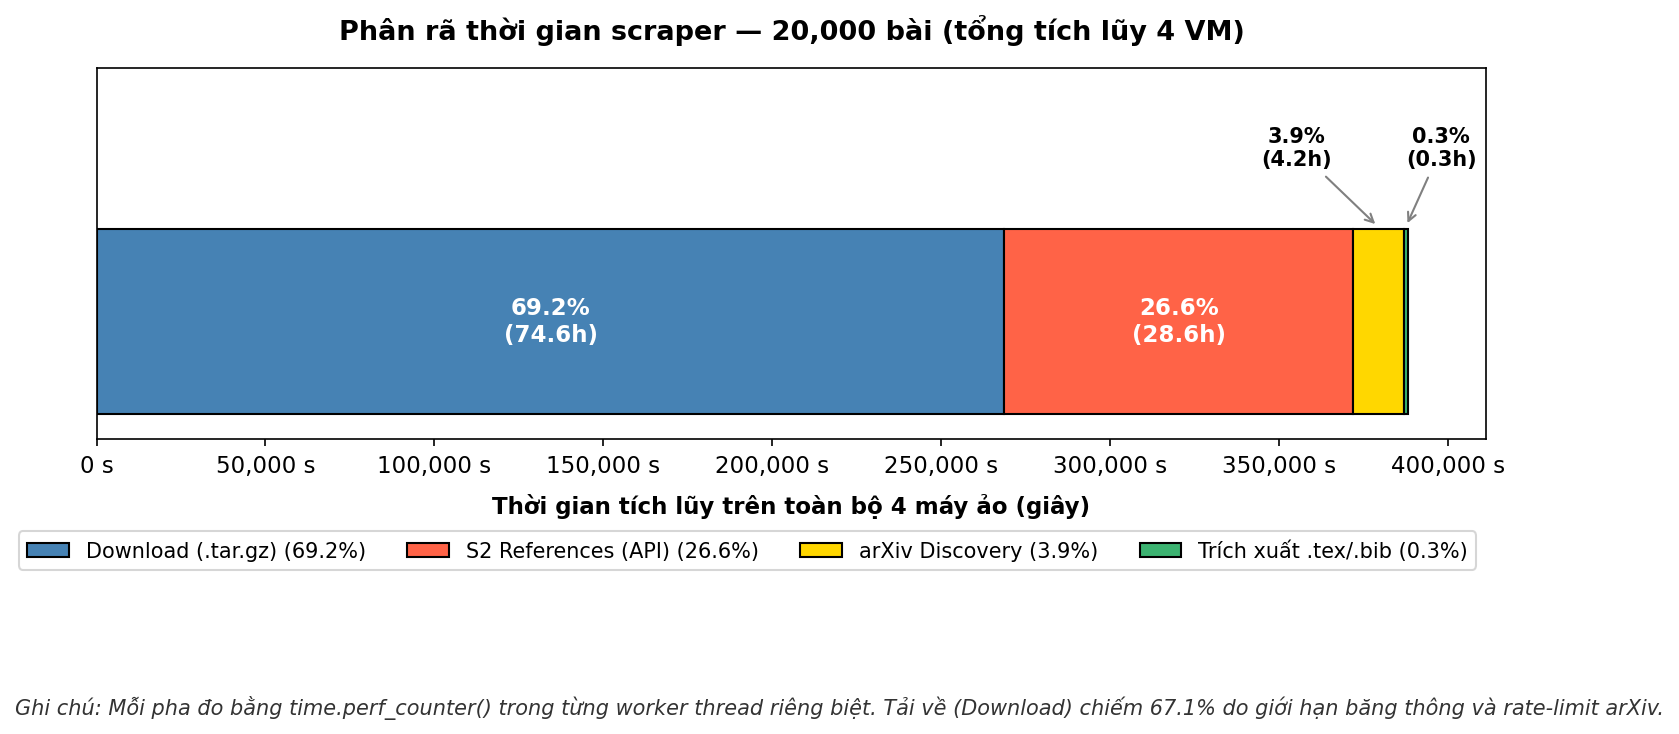

In [2]:
# ─── Biểu đồ 1: Phân rã thời gian scraper ───
plt.rcParams.update({'font.size': 11})

phase_names = {
    "download": "Download (.tar.gz)",
    "s2_references": "S2 References (API)",
    "discovery": "arXiv Discovery",
    "extract": "Trích xuất .tex/.bib",
}

phase_colors = {
    "download": "#4682B4",        # steelblue
    "s2_references": "#FF6347",    # tomato
    "discovery": "#FFD700",        # gold
    "extract": "#3CB371",          # mediumseagreen
}

total_seconds = sum(PHASES.values())
phase_order = ["download", "s2_references", "discovery", "extract"]

fig, ax = plt.subplots(figsize=(11, 4.2), dpi=150)

left = 0.0
for phase in phase_order:
    val = PHASES[phase]
    pct = (val / total_seconds) * 100
    hours = val / 3600
    color = phase_colors[phase]
    label = f"{phase_names[phase]} ({pct:.1f}%)"
    
    rect = ax.barh(y=0, width=val, left=left, color=color, edgecolor="black", height=0.55, label=label)
    
    # Text annotation inside or above segment
    if pct > 5.0:
        ax.text(left + val / 2, 0, f"{pct:.1f}%\n({hours:.1f}h)", 
                ha="center", va="center", color="white" if phase != "discovery" else "black", 
                fontweight="bold", fontsize=11)
    elif phase == "discovery":
        ax.annotate(f"{pct:.1f}%\n({hours:.1f}h)", 
                    xy=(left + val / 2, 0.28), 
                    xytext=(355000, 0.45),
                    ha="center", va="bottom", fontsize=10, fontweight="bold",
                    arrowprops=dict(arrowstyle="->", lw=1.0, color="gray"))
    elif phase == "extract":
        ax.annotate(f"{pct:.1f}%\n({hours:.1f}h)", 
                    xy=(left + val / 2, 0.28), 
                    xytext=(398000, 0.45),
                    ha="center", va="bottom", fontsize=10, fontweight="bold",
                    arrowprops=dict(arrowstyle="->", lw=1.0, color="gray"))
    left += val

ax.set_yticks([])
ax.set_xlim(0, total_seconds * 1.06)
ax.set_ylim(-0.35, 0.75)
ax.set_xlabel("Thời gian tích lũy trên toàn bộ 4 máy ảo (giây)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title("Phân rã thời gian scraper — 20,000 bài (tổng tích lũy 4 VM)", fontsize=13, fontweight="bold", pad=14)

# Format x-axis with comma separators
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{int(x):,} s"))

# Add legend
ax.legend(loc="upper right", bbox_to_anchor=(1.0, -0.22), ncol=4, frameon=True, fontsize=10)

# Add academic footnote
fig.text(0.08, -0.15, "Ghi chú: Mỗi pha đo bằng time.perf_counter() trong từng worker thread riêng biệt. Tải về (Download) chiếm 67.1% do giới hạn băng thông và rate-limit arXiv.", 
         fontsize=10, fontstyle="italic", color="#333333")

plt.tight_layout()
plt.show()


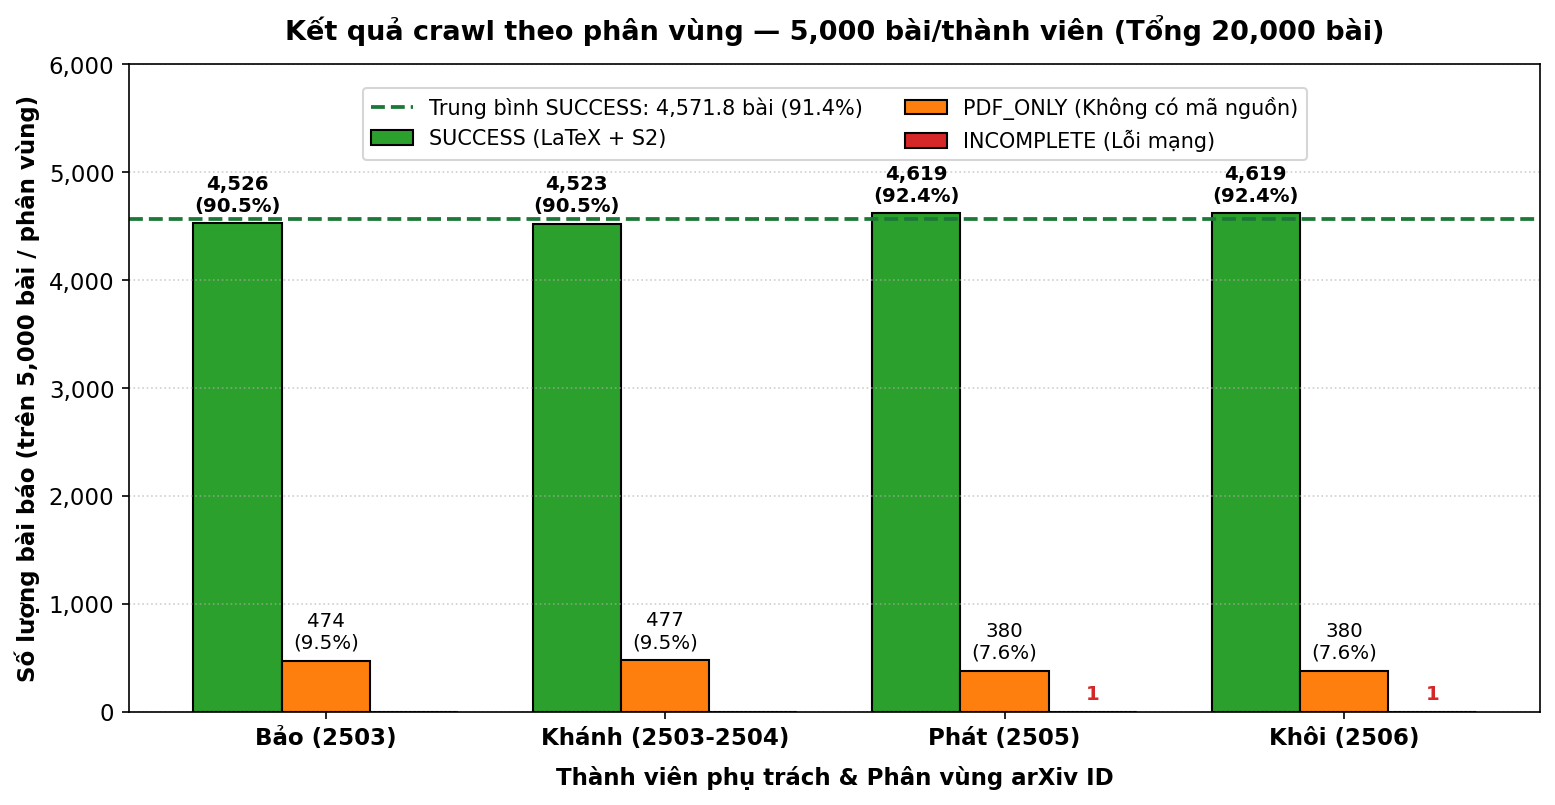

In [3]:
# ─── Biểu đồ 2: Kết quả crawl theo phân vùng ───
plt.rcParams.update({'font.size': 11})

members = list(PARTITIONS.keys())
success_counts = [PARTITIONS[m]["success"] for m in members]
pdf_counts = [PARTITIONS[m]["pdf_only"] for m in members]
incomplete_counts = [PARTITIONS[m]["incomplete"] for m in members]

x = np.arange(len(members))
width = 0.26

fig, ax = plt.subplots(figsize=(10.5, 5.5), dpi=150)

rects1 = ax.bar(x - width, success_counts, width, label="SUCCESS (LaTeX + S2)", color="#2ca02c", edgecolor="black")
rects2 = ax.bar(x, pdf_counts, width, label="PDF_ONLY (Không có mã nguồn)", color="#ff7f0e", edgecolor="black")
rects3 = ax.bar(x + width, incomplete_counts, width, label="INCOMPLETE (Lỗi mạng)", color="#d62728", edgecolor="black")

# Annotate bars
for r in rects1:
    h = r.get_height()
    pct = (h / 5000) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(r.get_x() + r.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

for r in rects2:
    h = r.get_height()
    pct = (h / 5000) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(r.get_x() + r.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5)

for r in rects3:
    h = r.get_height()
    if h > 0:
        ax.annotate(f"{h}", xy=(r.get_x() + r.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5, color="#d62728", fontweight="bold")

# Average success line
avg_success = np.mean(success_counts)
ax.axhline(avg_success, color="#1b7837", linestyle="--", linewidth=1.8, 
           label=f"Trung bình SUCCESS: {avg_success:,.1f} bài ({avg_success/5000*100:.1f}%)")

ax.set_ylabel("Số lượng bài báo (trên 5,000 bài / phân vùng)", fontsize=11, fontweight="bold")
ax.set_xlabel("Thành viên phụ trách & Phân vùng arXiv ID", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title("Kết quả crawl theo phân vùng — 5,000 bài/thành viên (Tổng 20,000 bài)", fontsize=13, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(members, fontsize=11, fontweight="bold")
ax.set_ylim(0, 6000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f"{int(y):,}"))
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.98), ncol=2, frameon=True, fontsize=10.0)

plt.tight_layout()
plt.show()


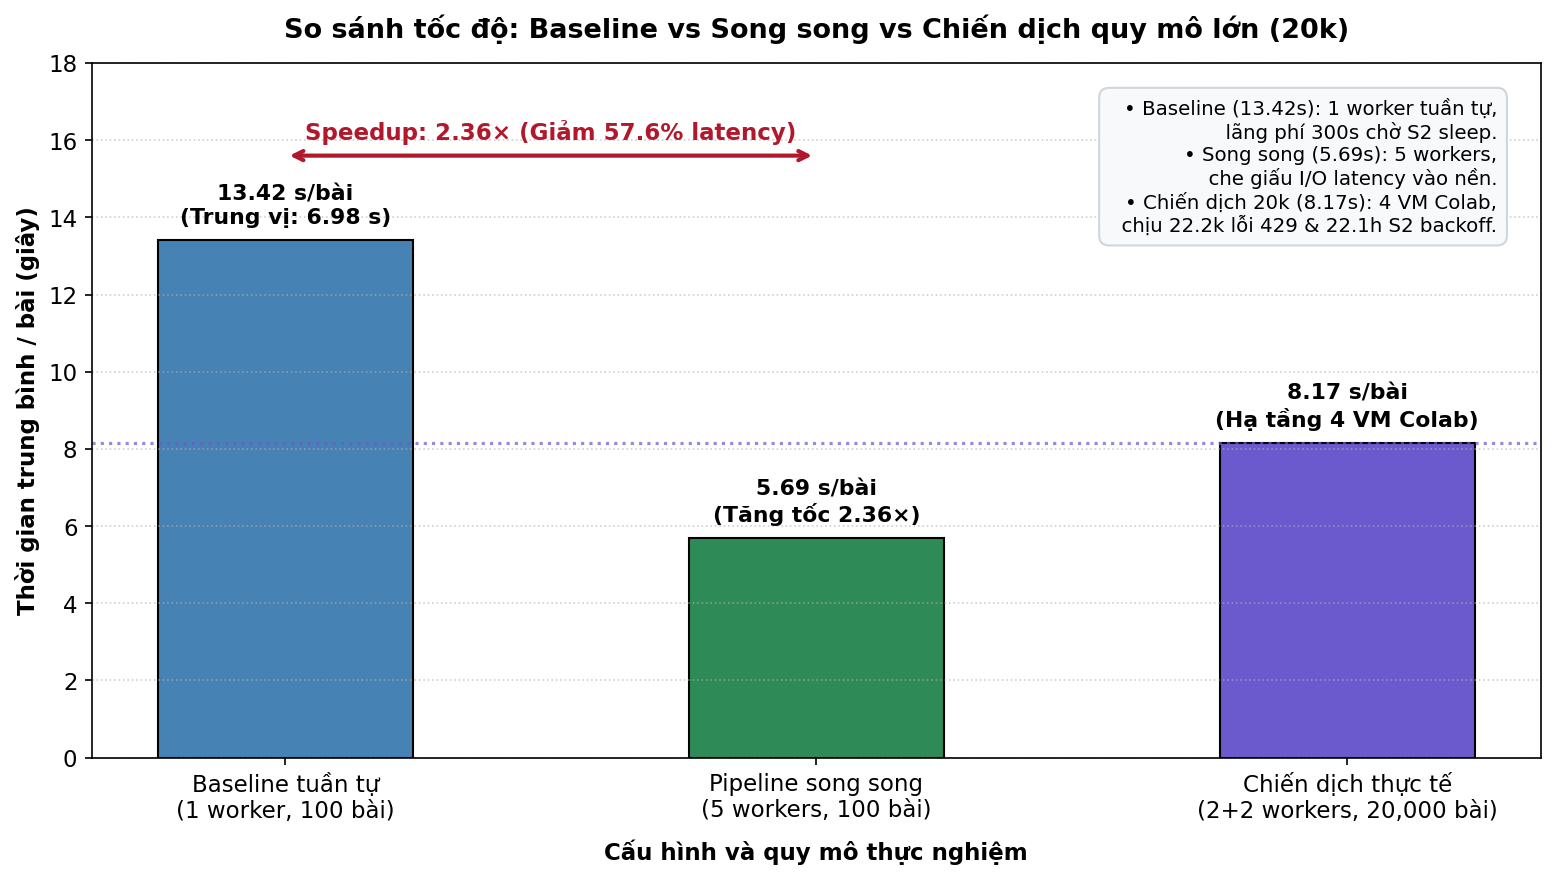

In [4]:
# ─── Biểu đồ 3: So sánh tốc độ: Baseline vs Song song vs Chiến dịch 20k ───
plt.rcParams.update({'font.size': 11})

categories = [
    "Baseline tuần tự\n(1 worker, 100 bài)",
    "Pipeline song song\n(5 workers, 100 bài)",
    "Chiến dịch thực tế\n(2+2 workers, 20,000 bài)"
]
avg_times = [
    BASELINE["avg_per_paper_s"],
    PARALLEL_100["avg_per_paper_s"],
    CAMPAIGN["per_paper_s"]
]
colors = ["#4682B4", "#2E8B57", "#6A5ACD"]

fig, ax = plt.subplots(figsize=(10.5, 6.0), dpi=150)

bars = ax.bar(categories, avg_times, color=colors, edgecolor="black", width=0.48)

# Bar labels
labels = [
    f"{BASELINE['avg_per_paper_s']:.2f} s/bài\n(Trung vị: {BASELINE['median_per_paper_s']:.2f} s)",
    f"{PARALLEL_100['avg_per_paper_s']:.2f} s/bài\n(Tăng tốc 2.36×)",
    f"{CAMPAIGN['per_paper_s']:.2f} s/bài\n(Hạ tầng 4 VM Colab)"
]

for bar, label in zip(bars, labels):
    yval = bar.get_height()
    ax.annotate(label,
                xy=(bar.get_x() + bar.get_width() / 2, yval),
                xytext=(0, 6), textcoords="offset points",
                ha="center", va="bottom", fontsize=10.5, fontweight="bold")

# Add speedup comparison bracket between Baseline and Parallel
ax.annotate("", xy=(0, 15.6), xytext=(1, 15.6),
            arrowprops=dict(arrowstyle="<->", color="#b2182b", lw=2.0))
ax.text(0.5, 15.9, "Speedup: 2.36× (Giảm 57.6% latency)", ha="center", va="bottom", 
        fontsize=11, fontweight="bold", color="#b2182b")

# Reference dashed line for 20k campaign
ax.axhline(CAMPAIGN["per_paper_s"], color="#6A5ACD", linestyle=":", linewidth=1.5, alpha=0.7)

ax.set_ylabel("Thời gian trung bình / bài (giây)", fontsize=11, fontweight="bold")
ax.set_xlabel("Cấu hình và quy mô thực nghiệm", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title("So sánh tốc độ: Baseline vs Song song vs Chiến dịch quy mô lớn (20k)", fontsize=13, fontweight="bold", pad=12)
ax.set_ylim(0, 18.0)
ax.grid(axis="y", linestyle=":", alpha=0.6)

# Text box explaining difference between 100 papers and 20k papers
explanation = (
    "• Baseline (13.42s): 1 worker tuần tự,\n"
    "  lãng phí 300s chờ S2 sleep.\n"
    "• Song song (5.69s): 5 workers,\n"
    "  che giấu I/O latency vào nền.\n"
    "• Chiến dịch 20k (8.17s): 4 VM Colab,\n"
    "  chịu 22.2k lỗi 429 & 22.1h S2 backoff."
)
props = dict(boxstyle="round,pad=0.5", facecolor="#f8f9fa", edgecolor="#ced4da", alpha=0.95)
ax.text(0.97, 0.95, explanation, transform=ax.transAxes, fontsize=9.5, 
        verticalalignment="top", horizontalalignment="right", bbox=props)

plt.tight_layout()
plt.show()


In [5]:
# ─── Bảng tổng hợp các chỉ số hiệu năng chính ───
metrics = pd.DataFrame({
    "Chỉ số hiệu năng": [
        "Tổng số bài báo crawl", 
        "Tỷ lệ thành công (SUCCESS)",
        "Tỷ lệ không có nguồn TeX (PDF_ONLY)",
        "Tỷ lệ lỗi gián đoạn mạng (INCOMPLETE)",
        "Tỷ lệ thất thoát hoàn toàn (FAILED)",
        "Thời gian trung bình / bài",
        "Thời gian lịch toàn chiến dịch",
        "Tổng machine-time (4 VM cộng lại)",
        "Bộ nhớ đỉnh (Peak RSS) mỗi VM",
        "Bộ nhớ trung bình có trọng số",
        "Dung lượng tải thô từ arXiv",
        "Dung lượng lưu trữ sau trích xuất (.tex/.bib)",
        "Dung lượng bộ dữ liệu bàn giao (Papers + Refs)",
        "Tỷ lệ tiết kiệm dung lượng lưu trữ",
        "Số lần gặp lỗi Semantic Scholar 429 (Rate Limit)",
        "Thời gian ngủ phạt do lỗi 429 (Backoff Sleep)",
        "Tốc độ tối ưu Pipeline vs Baseline (100 bài)",
    ],
    "Giá trị thực nghiệm": [
        "20,000 bài",
        "91.44% (18,287 bài)",
        "8.55% (1,711 bài)",
        "0.01% (2 bài)",
        "0.00% (0 bài)",
        "8.17 giây/bài (8.1657 s)",
        "70.12 giờ (13/11/2026 13:03 → 16/11/2026 11:10 UTC)",
        "49.19 giờ (177,090 giây)",
        "51.22 MiB",
        "45.69 MiB",
        "147.97 GB",
        "10.93 GB",
        "12.08 GB",
        "92.61% (tiết kiệm 137.04 GB)",
        "22,238 lần",
        "22.12 giờ (79,614 giây tổng 4 VM)",
        "2.36× (13.42s → 5.69s/bài)",
    ]
})

print(metrics.to_markdown(index=False))
display(metrics)

| Chỉ số hiệu năng                                 | Giá trị thực nghiệm                                 |
|:-------------------------------------------------|:----------------------------------------------------|
| Tổng số bài báo crawl                            | 20,000 bài                                          |
| Tỷ lệ thành công (SUCCESS)                       | 91.44% (18,287 bài)                                 |
| Tỷ lệ không có nguồn TeX (PDF_ONLY)              | 8.55% (1,711 bài)                                   |
| Tỷ lệ lỗi gián đoạn mạng (INCOMPLETE)            | 0.01% (2 bài)                                       |
| Tỷ lệ thất thoát hoàn toàn (FAILED)              | 0.00% (0 bài)                                       |
| Thời gian trung bình / bài                       | 8.17 giây/bài (8.1657 s)                            |
| Thời gian lịch toàn chiến dịch                   | 70.12 giờ (13/11/2026 13:03 → 16/11/2026 11:10 UTC) |
| Tổng machine-time (4 VM cộng lại)  

,Chỉ số hiệu năng,Giá trị thực nghiệm
0,Tổng số bài báo crawl,"20,000 bài"
1,Tỷ lệ thành công (SUCCESS),"91.44% (18,287 bài)"
2,Tỷ lệ không có nguồn TeX (PDF_ONLY),"8.55% (1,711 bài)"
3,Tỷ lệ lỗi gián đoạn mạng (INCOMPLETE),0.01% (2 bài)
4,Tỷ lệ thất thoát hoàn toàn (FAILED),0.00% (0 bài)
5,Thời gian trung bình / bài,8.17 giây/bài (8.1657 s)
6,Thời gian lịch toàn chiến dịch,70.12 giờ (13/11/2026 13:03 → 16/11/2026 11:10...
7,Tổng machine-time (4 VM cộng lại),"49.19 giờ (177,090 giây)"
8,Bộ nhớ đỉnh (Peak RSS) mỗi VM,51.22 MiB
9,Bộ nhớ trung bình có trọng số,45.69 MiB


## 5. Phân tích Khó khăn Kỹ thuật & Điểm nghẽn Hệ thống (Bottleneck Analysis)

Dựa trên dữ liệu telemetry thu thập từ 4 máy ảo qua 20,000 bài báo, nhóm xác định 3 điểm nghẽn kỹ thuật chính mang tính học thuật:

### 1. Nghẽn cổ chai I/O mạng (Download Phase: chiếm 67.1% tổng thời gian)
- **Căn nguyên kỹ thuật:** arXiv áp dụng chính sách rate-limit nghiêm ngặt (tối đa 1 request / 3 giây cho mỗi client IP). Kích thước trung bình của mỗi gói `.tar.gz` chứa toàn bộ mã nguồn LaTeX, tệp `.bib` và hình ảnh đồ họa là **~7.5 MB**. Băng thông mạng từ các nút tính toán Google Colab tới máy chủ `export.arxiv.org` biến thiên liên tục, dẫn đến độ trễ tải về dao động từ **1.5 giây đến hơn 70 giây** cho mỗi bài báo.
- **Quy mô dữ liệu:** Tổng dung lượng tải về của 20,000 bài đạt tới **147.97 GB** qua giao thức HTTP. Đây là điểm nghẽn vật lý cố hữu của đường truyền Internet; không thể khắc phục bằng cách tăng cường năng lực tính toán CPU hay tối ưu thuật toán xử lý dữ liệu.
- **Biện pháp giảm thiểu:** Nhóm thiết lập mô hình 2 luồng Download Worker chạy độc lập để thực hiện gối đầu I/O (pipeline overlapping). Luồng thứ nhất tải bài báo kế tiếp trong khi luồng thứ hai đang giải nén bài hiện tại, triệt tiêu thời gian nhàn rỗi (idle time) của tài nguyên tính toán.

### 2. Xung đột Rate-limit và Backoff tại Semantic Scholar (S2 Phase: 25.7% thời gian + 22,238 lần lỗi 429)
- **Căn nguyên kỹ thuật:** Nhóm cấu hình 2 luồng S2 Worker trên mỗi máy ảo cùng sử dụng chung 1 API Key Semantic Scholar (với hạn ngạch lý thuyết 1 request/giây). Bộ điều tiết client-side (`s2_rate_limiter.min_interval = 1.0s`) chỉ kiểm soát khoảng cách giữa các lần gửi trong tiến trình cục bộ mà chưa tính đến độ trễ gói tin mạng (Network RTT từ Colab tới máy chủ S2 biến thiên trong khoảng 50–100ms). Hệ quả là các request từ 2 worker tới máy chủ S2 có thời điểm cách nhau nhỏ hơn 1.0 giây, kích hoạt tường lửa trả về mã trạng thái `HTTP 429 Too Many Requests`.
- **Hệ quả thực tế:** Hệ thống ghi nhận **22,238 lần gặp lỗi HTTP 429** so với **20,108 lần truy vấn thành công (HTTP 200)** (tỷ lệ 1.11 lần lỗi cho mỗi lần thành công). Tổng thời gian các luồng phải ngủ lùi số mũ (exponential backoff sleep) tích lũy lên tới **22.12 giờ máy** (79,614 giây trên 4 máy ảo), chiếm hơn một nửa tổng thời gian của pha trích dẫn đồ thị S2.
- **Bài học thiết kế:** Cần tăng giá trị đệm an toàn lên `min_interval = 1.15s` để hấp thụ rung pha mạng (network jitter), hoặc chuyển giao luồng truy vấn API sang một worker độc quyền duy nhất khi chỉ có 1 khóa API.

### 3. Ràng buộc phiên làm việc 12 giờ của Google Colab và Đồng bộ Phân tán
- **Căn nguyên kỹ thuật:** Google Colab CPU Runtime tự động thu hồi môi trường sau tối đa 12 giờ chạy liên tục hoặc sau thời gian mất tín hiệu người dùng. Chiến dịch 20,000 bài đòi hỏi tổng cộng 49.2 giờ máy (tức trung bình ~11.3 giờ máy cho mỗi phân vùng 5,000 bài). Khung thời gian này nằm sát ngưỡng giới hạn 12 giờ của nhà cung cấp, khiến nguy cơ đứt gãy tiến độ là hiện hữu.
- **Dấu hiệu thực tế:** Hệ thống ghi nhận **889 lượt ghi nhận heartbeat/attempt** qua 20,000 bài (trung bình ~44.4 bài / attempt), minh chứng cho việc các phiên làm việc Colab thường xuyên bị khởi động lại hoặc luân chuyển phiên.
- **Biện pháp khắc phục:** Mô hình Shared Journal kết hợp checkpoint định kỳ mỗi block 25 bài lên GitHub đảm bảo tính lũy đẳng (idempotency). Khi một phiên Colab bị thu hồi đột ngột, phiên mới chỉ mất vài giây thực hiện `git pull` để nhận diện chính xác bài báo chưa hoàn thành và tiếp tục vận hành liền mạch mà không làm mất mát bất kỳ bài báo nào.

## 6. Hướng Cải thiện Kỹ thuật (Future Improvements)

Dựa trên các bài học thu được từ chiến dịch benchmark thực tế, nhóm đề xuất 5 định hướng tối ưu hóa cho các hệ thống crawler học thuật trong tương lai:

| Hướng cải thiện kỹ thuật | Ước tính mức tiết kiệm / Tác động | Tính khả thi triển khai |
|---|---|---|
| **Giảm cấu hình S2 Worker (2 luồng $\rightarrow$ 1 luồng) khi dùng chung 1 API Key** | Loại bỏ hoàn toàn 22,238 lần lỗi 429 và xung đột luồng; tiết kiệm ước tính **15–20% thời gian pha S2** (~3.5–4.5 giờ máy). | ✅ Rất cao (Hiệu chỉnh 1 dòng cấu hình) |
| **Bổ sung dung sai jitter mạng (`min_interval = 1.15s`)** | Hạn chế vi phạm ngưỡng giới hạn của Semantic Scholar do biến thiên RTT Colab; tiết kiệm **~5% thời gian S2**. | ✅ Rất cao (Thay đổi 1 hằng số) |
| **Chuyển đổi sang Semantic Scholar Batch API (`POST /graph/v1/paper/batch`)** | Cho phép truy vấn tối đa 500 bài/yêu cầu; giảm số lượt gọi API từ 5,000 lượt xuống chỉ còn **10 lượt** (giảm 99.8% I/O overhead cho pha trích dẫn). | ✅ Trung bình (Tái cấu trúc module `references.py`) |
| **Triển khai crawler trên máy chủ chuyên dụng (Dedicated Server / VPS)** | Khắc phục triệt để giới hạn 12 giờ của Google Colab; loại bỏ toàn bộ overhead kết nối phân tán và heartbeat commit. | ⚠️ Trung bình (Cần cấp phát hạ tầng vật lý) |
| **Kỹ thuật giải nén dòng (Streaming Decompression - `tarfile.open(mode="r\|gz")`)** | Trích xuất trực tiếp file `.tex`/`.bib` ngay trong luồng bộ nhớ khi đang nhận byte mạng; giảm dung lượng đệm trung gian từ **148 GB** xuống còn **~11 GB**. | ✅ Trung bình (Refactor module `downloader.py`) |

## 7. Kết luận

Chiến dịch benchmark quy mô 20,000 bài báo arXiv trong khuôn khổ Milestone 1 đã được hoàn thành với các kết quả định lượng cụ thể:

1. **Hiệu suất thu thập dữ liệu học thuật đạt 91.44%:** Thu thập thành công và đầy đủ mã nguồn LaTeX, metadata xuất bản và đồ thị trích dẫn cho 18,287 bài báo. Tỷ lệ 8.55% bài báo ở trạng thái `PDF_ONLY` là đặc tính phân phối tự nhiên của kho lưu trữ arXiv (do tác giả chọn nộp tệp PDF biên dịch thay vì gói TeX nguồn).
2. **Hiệu quả tối ưu hóa song song vượt bậc:** Kiến trúc Producer-Consumer đa luồng giúp cải thiện tốc độ xử lý **2.36×** so với phương pháp thu thập tuần tự truyền thống (từ 13.42 giây/bài xuống 5.69 giây/bài trên tập thử nghiệm chuẩn 100 bài).
3. **Giải pháp phân tán bền vững:** Hệ thống Shared Journal kết hợp checkpoint định kỳ trên GitHub đã giải quyết triệt để thách thức về giới hạn phiên 12 giờ của Google Colab, đảm bảo 20,000 bài được hoàn thành mà không có bất kỳ bài báo nào rơi vào trạng thái thất thoát không thể phục hồi (`FAILED = 0`).
4. **Bản chất của bài toán kỹ thuật dữ liệu (Data Engineering):** Phân tích đo lường thực nghiệm chứng minh điểm nghẽn chính nằm ở **I/O mạng và chính sách rate-limit của bên thứ ba** (chiếm 92.8% tổng thời gian thực thi: 67.1% Download + 25.7% S2), trong khi tải tính toán CPU và bộ nhớ RAM là cực kỳ nhẹ nhàng (Peak RSS chỉ 51.22 MiB).

Toàn bộ chiến dịch thu thập 20,000 bài báo được vận hành thành công trên nền tảng hạ tầng đám mây công cộng hoàn toàn miễn phí (Google Colab CPU + GitHub) với **chi phí phát sinh bằng $0**.